# Đồ án NLP — Phát hiện tin giả COVID-19 (CONSTRAINT@AAAI2021)
**Thành viên phụ trách:** Lê Nguyễn Ngọc Bình (Nhóm 5)  
**Nhánh thực nghiệm:** `RoBERTa-base` (5 seed: `42, 123, 2024, 2025, 2026`), Kiểm tra rò rỉ dữ liệu, Đánh giá 5 tiêu chí, Phân tích lỗi tự động (FP/FN), Thiết kế thí nghiệm cải tiến & Demo.

---
### Quy ước chuẩn thống nhất toàn nhóm
- **Bộ dữ liệu:** `6.420 Train / 2.140 Validation / 2.140 Test` (10.700 bài đăng tiếng Anh).
- **Ánh xạ nhãn nhất quán:** `fake = 0`, `real = 1` (lưu trực tiếp trong `config.json` và đọc qua `model.config.id2label`).
- **Chỉ số đánh giá phân loại nhị phân (2 lớp):** Binary Precision / Recall / F1 cho lớp cần phát hiện (`fake = 0`), F1 lớp `real = 1`, ROC-AUC, kèm `F1 weighted` để đối chiếu với bài báo gốc Patwa et al. (2021).
- **Chống rò rỉ dữ liệu:** Chọn checkpoint và siêu tham số/ngưỡng hoàn toàn dựa trên tập `Validation`; chấm điểm cả tập `Test` gốc lẫn tập `Test` đã loại bỏ các dòng trùng lặp với `Train`.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Cell 1: Cài đặt thư viện, Thiết lập 5 Seed & Hàm đánh giá Nhị phân (2 lớp)

In [ ]:
# ==============================================================================
# CELL 1: CÀI ĐẶT THƯ VIỆN, 5 SEED & METRICS CHUẨN CHO BÀI TOÁN NHỊ PHÂN (2 LỚP)
# ==============================================================================
!pip install -q transformers datasets evaluate scikit-learn accelerate matplotlib seaborn

import os
import re
import glob
import html
import json
import time
import random
import shutil
import inspect
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset
from transformers import (
    RobertaTokenizer,
    RobertaForSequenceClassification,
    Trainer,
    TrainingArguments
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

# 1. Quy ước nhãn thống nhất toàn nhóm: fake = 0, real = 1
LABEL2ID = {'fake': 0, 'real': 1}
ID2LABEL = {0: 'fake', 1: 'real'}

# Chạy 5 seed (>= 5 seed) để tính Mean ± Sample Std đáng tin cậy hơn 3 seed
SEEDS = [42, 123, 2024, 2025, 2026]
MODEL_NAME = 'roberta-base'
MAX_LEN = 128

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"

# Hỗ trợ tương thích cả bản Transformers 4.x và 5.x cho tham số eval_strategy
TA_PARAMS = inspect.signature(TrainingArguments.__init__).parameters
EVAL_STRATEGY_KEY = "eval_strategy" if "eval_strategy" in TA_PARAMS else "evaluation_strategy"

print(f"✅ Thiết bị thực thi: {GPU_NAME}")
print(f"✅ Danh sách {len(SEEDS)} seed: {SEEDS} | Mapping: {LABEL2ID}")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# 2. Hàm tính metrics chuẩn cho PHÂN LOẠI NHỊ PHÂN (2 lớp)
# Dùng Binary Precision/Recall/F1 cho lớp mục tiêu FAKE (pos_label=0) và ROC-AUC,
# đồng thời tính thêm F1 lớp REAL (1) và F1 weighted để đối chiếu bài báo gốc.
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    prec_fake = precision_score(labels, preds, pos_label=0, zero_division=0)
    rec_fake  = recall_score(labels, preds, pos_label=0, zero_division=0)
    f1_fake   = f1_score(labels, preds, pos_label=0, zero_division=0)

    prec_real = precision_score(labels, preds, pos_label=1, zero_division=0)
    rec_real  = recall_score(labels, preds, pos_label=1, zero_division=0)
    f1_real   = f1_score(labels, preds, pos_label=1, zero_division=0)

    f1_w = f1_score(labels, preds, average='weighted')
    roc_auc = roc_auc_score(labels, probs[:, 1])

    return {
        'accuracy': acc,
        'f1_weighted': f1_w,
        'roc_auc': roc_auc,
        'f1_fake': f1_fake,
        'prec_fake': prec_fake,
        'rec_fake': rec_fake,
        'f1_real': f1_real,
        'prec_real': prec_real,
        'rec_real': rec_real
    }

✅ Thiết bị thực thi: Tesla T4
✅ Danh sách 5 seed: [42, 123, 2024, 2025, 2026] | Mapping: {'fake': 0, 'real': 1}


## Cell 2: Tải dữ liệu chung, Khảo sát đa góc độ & Kiểm tra rò rỉ dữ liệu

In [ ]:
# ==============================================================================
# CELL 2: TẢI DỮ LIỆU CHUNG, KHẢO SÁT ĐA GÓC ĐỘ & KIỂM TRA RÒ RỈ DỮ LIỆU
# ==============================================================================
os.makedirs("./roberta_results", exist_ok=True)
HF_BASE_URL = "https://huggingface.co/datasets/nanyy1025/covid_fake_news/resolve/main"

def load_split_csv(split_name):
    local_paths = [f"data/{split_name}.csv", f"/content/{split_name}.csv", f"{split_name}.csv"]
    for p in local_paths:
        if os.path.exists(p):
            df = pd.read_csv(p)
            break
    else:
        df = pd.read_csv(f"{HF_BASE_URL}/{split_name}.csv")

    text_col = 'tweet' if 'tweet' in df.columns else ('text' if 'text' in df.columns else df.columns[1])
    df = df.rename(columns={text_col: 'tweet'})

    raw_label = df['label'].astype(str).str.strip().str.lower()
    df['label'] = raw_label.map({'fake': 0, 'real': 1, '0': 0, '1': 1})
    assert df['label'].notna().all(), f"Phát hiện nhãn lạ trong tập {split_name}!"
    df['label'] = df['label'].astype(int)
    return df

df_train = load_split_csv("train")
df_val   = load_split_csv("val")
df_test  = load_split_csv("test")

# --- 1. KIỂM TRA RÒ RỈ DỮ LIỆU (EXACT & NORMALIZED DUPLICATES) ---
def normalize_for_leak_check(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)   # Bỏ link rút gọn t.co khác nhau
    text = re.sub(r'[^\w\s]', '', text)            # Bỏ dấu câu
    text = re.sub(r'\s+', ' ', text).strip()
    return text

for d in [df_train, df_val, df_test]:
    d['norm_text'] = d['tweet'].apply(normalize_for_leak_check)

train_exact_set = set(df_train['tweet'])
train_norm_set  = set(df_train['norm_text'])

val_exact_leak  = df_val['tweet'].isin(train_exact_set).sum()
test_exact_leak = df_test['tweet'].isin(train_exact_set).sum()

val_norm_leak_mask  = df_val['norm_text'].isin(train_norm_set)
test_norm_leak_mask = df_test['norm_text'].isin(train_norm_set)

# Đánh dấu các dòng Test sạch (không trùng nội dung chuẩn hóa với Train)
df_test['is_leaked_from_train'] = test_norm_leak_mask
df_test_clean = df_test[~df_test['is_leaked_from_train']].reset_index(drop=True)

leakage_report = {
    "train_rows": len(df_train),
    "val_rows": len(df_val),
    "test_rows": len(df_test),
    "missing_values_total": int(df_train['tweet'].isna().sum() + df_val['tweet'].isna().sum() + df_test['tweet'].isna().sum()),
    "exact_overlap_train_val": int(val_exact_leak),
    "exact_overlap_train_test": int(test_exact_leak),
    "normalized_overlap_train_val_rows": int(val_norm_leak_mask.sum()),
    "normalized_overlap_train_test_rows": int(test_norm_leak_mask.sum()),
    "test_clean_rows_after_removing_leak": len(df_test_clean)
}

with open("./roberta_results/data_leakage_report.json", "w", encoding="utf-8") as f:
    json.dump(leakage_report, f, indent=2, ensure_ascii=False)

print("=== BÁO CÁO KIỂM TRA RÒ RỈ DỮ LIỆU ===")
for k, v in leakage_report.items():
    print(f"  - {k}: {v}")

# --- 2. KHẢO SÁT ĐA GÓC ĐỘ VẤN ĐỀ CỦA DỮ LIỆU TRAIN ---
def inspect_text_issues(df):
    s = df['tweet'].astype(str)
    stats = pd.DataFrame({
        'label': df['label'],
        'word_count': s.apply(lambda x: len(x.split())),
        'has_url': s.str.contains(r'http\S+|www\.\S+', regex=True),
        'has_hashtag': s.str.contains(r'#\w+', regex=True),
        'has_mention': s.str.contains(r'@\w+', regex=True),
        'starts_with_rt': s.str.match(r'^RT\s+@', case=False),
        'has_html_entity': s.str.contains(r'&amp;|&lt;|&gt;|&quot;|&#\d+;', regex=True),
        'has_non_ascii_special': s.str.contains(r'[^\x00-\x7F]', regex=True),
        'has_question_mark': s.str.contains(r'\?', regex=True),
        'has_exclamation': s.str.contains(r'!', regex=True),
        'is_truncated': s.str.contains(r'\.\.\.|…', regex=True)
    })
    summary = stats.groupby('label').mean().T
    summary.columns = ['Fake (0)', 'Real (1)']
    summary['Chênh lệch (Real - Fake)'] = summary['Real (1)'] - summary['Fake (0)']
    return summary

df_eda_issues = inspect_text_issues(df_train)
df_eda_issues.to_csv("./roberta_results/eda_data_issues_train.csv")
print("\n=== KHẢO SÁT ĐA GÓC ĐỘ VẤN ĐỀ DỮ LIỆU (TỈ LỆ / TRUNG BÌNH) ===")
display(df_eda_issues.round(4))

# Tokenize dữ liệu gốc cho RoBERTa
tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)

def build_hf_dataset(df, text_col='tweet'):
    sub_df = df[[text_col, 'label']].rename(columns={text_col: 'tweet'}).reset_index(drop=True)
    ds = Dataset.from_pandas(sub_df, preserve_index=False)
    return ds.map(
        lambda x: tokenizer(x['tweet'], padding='max_length', truncation=True, max_length=MAX_LEN),
        batched=True
    )

train_dataset      = build_hf_dataset(df_train)
val_dataset        = build_hf_dataset(df_val)
test_dataset       = build_hf_dataset(df_test)
test_clean_dataset = build_hf_dataset(df_test_clean)
print("✅ Đã Tokenize xong Train, Val, Test gốc và Test sạch rò rỉ!")

=== BÁO CÁO KIỂM TRA RÒ RỈ DỮ LIỆU ===
  - train_rows: 6420
  - val_rows: 2140
  - test_rows: 2140
  - missing_values_total: 0
  - exact_overlap_train_val: 1
  - exact_overlap_train_test: 0
  - normalized_overlap_train_val_rows: 81
  - normalized_overlap_train_test_rows: 75
  - test_clean_rows_after_removing_leak: 2065

=== KHẢO SÁT ĐA GÓC ĐỘ VẤN ĐỀ DỮ LIỆU (TỈ LỆ / TRUNG BÌNH) ===


,Fake (0),Real (1),Chênh lệch (Real - Fake)
word_count,21.8654,31.6765,9.8111
has_url,0.3271,0.6932,0.3660
has_hashtag,0.1863,0.5101,0.3238
has_mention,0.0775,0.2789,0.2014
starts_with_rt,0.0062,0.0726,0.0664
has_html_entity,0.0170,0.0938,0.0768
has_non_ascii_special,0.2297,0.3536,0.1238
has_question_mark,0.1049,0.0211,-0.0838
has_exclamation,0.0660,0.0155,-0.0505
is_truncated,0.0258,0.0810,0.0551


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/6420 [00:00<?, ? examples/s]

Map:   0%|          | 0/2140 [00:00<?, ? examples/s]

Map:   0%|          | 0/2140 [00:00<?, ? examples/s]

Map:   0%|          | 0/2065 [00:00<?, ? examples/s]

✅ Đã Tokenize xong Train, Val, Test gốc và Test sạch rò rỉ!


## Cell 3: Fine-tune RoBERTa-base qua 5 Seed + Đo chi phí tính toán & Vẽ Learning Curves


🚀 ĐANG FINE-TUNE ROBERTA-BASE | SEED = 42 (1/5)


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (40 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,F1 Weighted,Roc Auc,F1 Fake,Prec Fake,Rec Fake,F1 Real,Prec Real,Rec Real
0.039085,0.146930,3,0.971495,0.971474,0.996668,0.969697,0.982880,0.956863,0.973092,0.961639,0.984821



=== TỔNG HỢP VALIDATION QUA 5 SEED ===


,seed,gpu_name,total_params,val_accuracy,val_f1_weighted,val_f1_fake,val_roc_auc,train_time_sec,peak_vram_gb,best_checkpoint
0,42,Tesla T4,124647170,0.976636,0.976623,0.975248,0.996554,163.55,2.407,./roberta_checkpoints/seed_42/checkpoint-804
1,123,Tesla T4,124647170,0.978505,0.978486,0.977114,0.997297,161.69,2.411,./roberta_checkpoints/seed_123/checkpoint-1206
2,2024,Tesla T4,124647170,0.971495,0.971474,0.969697,0.996667,159.61,2.409,./roberta_checkpoints/seed_2024/checkpoint-1206
3,2025,Tesla T4,124647170,0.976168,0.976163,0.974889,0.996930,161.78,2.410,./roberta_checkpoints/seed_2025/checkpoint-804
4,2026,Tesla T4,124647170,0.971495,0.971474,0.969697,0.996668,162.59,2.417,./roberta_checkpoints/seed_2026/checkpoint-1206


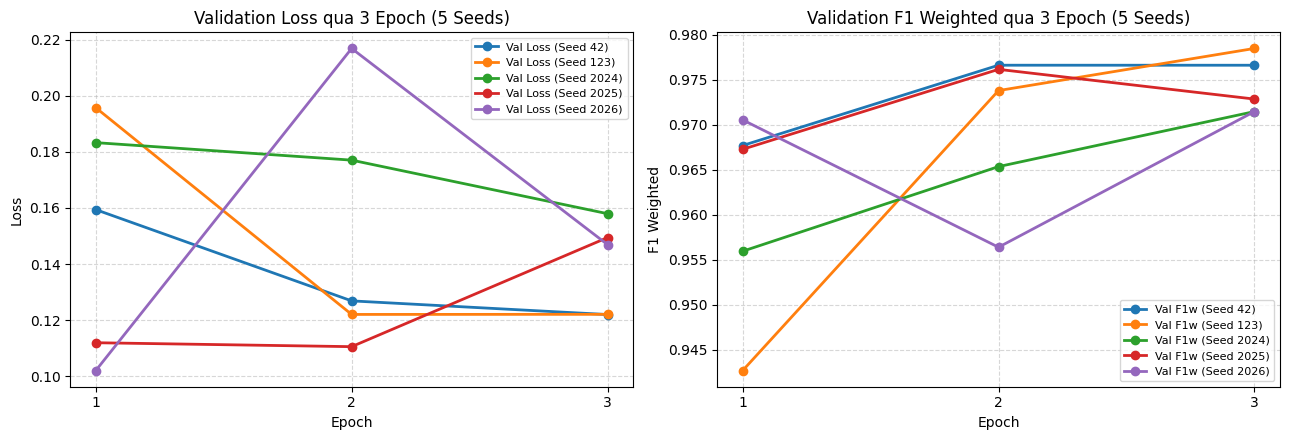

In [ ]:
# ==============================================================================
# CELL 3: FINE-TUNE ROBERTA-BASE QUA 5 SEED + ĐO CHI PHÍ (THỜI GIAN, VRAM, PARAMS)
# ==============================================================================
os.makedirs("./roberta_checkpoints", exist_ok=True)

val_summary_list = []
epoch_progression_list = []
best_ckpt_paths = {}

for seed in SEEDS:
    set_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    start_time = time.time()

    print(f"\n" + "="*68)
    print(f"🚀 ĐANG FINE-TUNE ROBERTA-BASE | SEED = {seed} ({SEEDS.index(seed)+1}/{len(SEEDS)})")
    print("="*68)

    model = RobertaForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label=ID2LABEL,
        label2id=LABEL2ID
    )
    total_params = sum(p.numel() for p in model.parameters())
    out_dir = f"./roberta_checkpoints/seed_{seed}"

    ta_kwargs = {
        "output_dir": out_dir,
        "num_train_epochs": 3,
        "per_device_train_batch_size": 16,
        "per_device_eval_batch_size": 16,
        "learning_rate": 1.5e-5,
        "lr_scheduler_type": "cosine",
        "warmup_steps": 72,              # ~6% của 1206 bước, tương thích mọi bản Transformers
        "weight_decay": 0.02,
        EVAL_STRATEGY_KEY: "epoch",
        "save_strategy": "epoch",
        "logging_strategy": "epoch",
        "save_total_limit": 1,
        "load_best_model_at_end": True,
        "metric_for_best_model": "f1_weighted",
        "greater_is_better": True,
        "fp16": torch.cuda.is_available(),
        "seed": seed,
        "report_to": "none"
    }
    training_args = TrainingArguments(**ta_kwargs)

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        compute_metrics=compute_metrics
    )

    trainer.train()
    train_time = time.time() - start_time
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024**3) if torch.cuda.is_available() else 0.0

    # Lưu best model, tokenizer và training_args.json (minh bạch cấu hình)
    best_dir = f"./roberta_checkpoints/seed_{seed}/best_model"
    trainer.model.save_pretrained(best_dir)
    tokenizer.save_pretrained(best_dir)
    with open(os.path.join(best_dir, "training_args.json"), "w", encoding="utf-8") as f:
        json.dump(training_args.to_dict(), f, indent=2, default=str)
    best_ckpt_paths[seed] = best_dir

    # Ghi lịch sử từng epoch
    train_losses = [x['loss'] for x in trainer.state.log_history if 'loss' in x and 'eval_loss' not in x]
    eval_logs    = [x for x in trainer.state.log_history if 'eval_f1_weighted' in x]

    for ep_idx, ev in enumerate(eval_logs):
        tr_loss = train_losses[ep_idx] if ep_idx < len(train_losses) else np.nan
        epoch_progression_list.append({
            'seed': seed,
            'epoch': int(round(ev['epoch'])),
            'train_loss': tr_loss,
            'val_loss': ev['eval_loss'],
            'val_accuracy': ev['eval_accuracy'],
            'val_f1_weighted': ev['eval_f1_weighted'],
            'val_f1_fake': ev['eval_f1_fake'],
            'val_roc_auc': ev['eval_roc_auc']
        })

    val_metrics = trainer.evaluate(val_dataset)
    val_summary_list.append({
        'seed': seed,
        'gpu_name': GPU_NAME,
        'total_params': total_params,
        'val_accuracy': val_metrics['eval_accuracy'],
        'val_f1_weighted': val_metrics['eval_f1_weighted'],
        'val_f1_fake': val_metrics['eval_f1_fake'],
        'val_roc_auc': val_metrics['eval_roc_auc'],
        'train_time_sec': round(train_time, 2),
        'peak_vram_gb': round(peak_vram_gb, 3),
        'best_checkpoint': trainer.state.best_model_checkpoint
    })

df_val_summary = pd.DataFrame(val_summary_list)
df_val_summary.to_csv("./roberta_results/roberta_val_5seeds_summary.csv", index=False)

df_epochs = pd.DataFrame(epoch_progression_list)
df_epochs.to_csv("./roberta_results/roberta_epoch_progression_5seeds.csv", index=False)

print("\n=== TỔNG HỢP VALIDATION QUA 5 SEED ===")
display(df_val_summary.round(6))

# Vẽ biểu đồ Learning Curves qua 3 Epoch của 5 Seed
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for seed, grp in df_epochs.groupby("seed"):
    ax1.plot(grp["epoch"], grp["val_loss"], marker='o', linewidth=2, label=f"Val Loss (Seed {seed})")
    ax2.plot(grp["epoch"], grp["val_f1_weighted"], marker='o', linewidth=2, label=f"Val F1w (Seed {seed})")

ax1.set_title("Validation Loss qua 3 Epoch (5 Seeds)")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_xticks([1, 2, 3]); ax1.grid(True, linestyle='--', alpha=0.5); ax1.legend(fontsize=8)
ax2.set_title("Validation F1 Weighted qua 3 Epoch (5 Seeds)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("F1 Weighted"); ax2.set_xticks([1, 2, 3]); ax2.grid(True, linestyle='--', alpha=0.5); ax2.legend(fontsize=8)
plt.tight_layout()
plt.savefig("./roberta_results/roberta_learning_curves_5seeds.png", dpi=300)
plt.show()

## Cell 4: Đánh giá 5 Tiêu chí trên tập Test gốc & Test sạch rò rỉ + Đo độ trễ suy luận

🏆 Seed tốt nhất theo Validation: Seed 123 (Val F1w = 0.978486)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

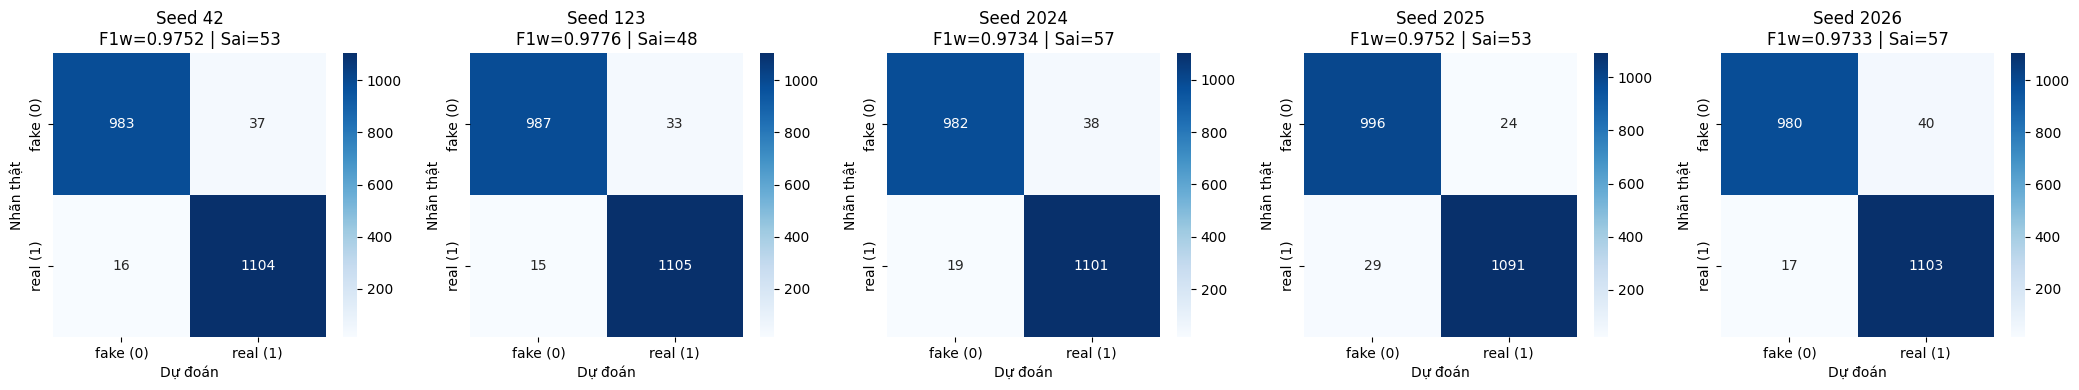

,seed,acc_test,f1_weighted_test,f1_fake_binary,prec_fake,rec_fake,f1_real,roc_auc,acc_test_no_leak,f1_w_test_no_leak,TN_fake_ok,FP_fake_as_real,FN_real_as_fake,TP_real_ok,total_errors,latency_ms_per_sample,throughput_samples_per_sec,model_size_mb
0,42,0.975234,0.975220,0.973749,0.983984,0.963725,0.976559,0.997182,0.974334,0.974315,983,37,16,1104,53,10.21,98.0,475.5
1,123,0.977570,0.977560,0.976261,0.985030,0.967647,0.978742,0.997149,0.976755,0.976741,987,33,15,1105,48,10.37,96.5,475.5
2,2024,0.973364,0.973351,0.971796,0.981019,0.962745,0.974768,0.995941,0.972397,0.972379,982,38,19,1101,57,10.20,98.0,475.5
3,2025,0.975234,0.975236,0.974083,0.971707,0.976471,0.976286,0.996746,0.974334,0.974338,996,24,29,1091,53,10.12,98.9,475.5
4,2026,0.973364,0.973348,0.971740,0.982949,0.960784,0.974812,0.996792,0.972397,0.972374,980,40,17,1103,57,10.16,98.5,475.5



=== BÁO CÁO 5 TIÊU CHÍ (MEAN ± SAMPLE STD QUA 5 SEED, ddof=1) ===
  acc_test                : 0.974953 ± 0.001736
  f1_weighted_test        : 0.974943 ± 0.001738
  f1_fake_binary          : 0.973526 ± 0.001872
  prec_fake               : 0.980938 ± 0.005368
  rec_fake                : 0.966275 ± 0.006224
  roc_auc                 : 0.996762 ± 0.000501
  f1_w_test_no_leak       : 0.974029 ± 0.001802
  total_errors            : 53.600000 ± 3.714835
  latency_ms_per_sample   : 10.212000 ± 0.095237

=== ĐÁNH GIÁ THỰC TIỄN 5 TIÊU CHÍ SO VỚI BASELINE ===


,Mô hình,F1 Weighted Test,Độ ổn định (Std),Thời gian Train,Peak VRAM / Dung lượng,Độ trễ suy luận
0,Baseline SVM + TF-IDF + stats,0.949069,0.0000 (tất định),~0.02 giây (CPU),CPU / ~5 MB,< 0.5 ms/câu
1,RoBERTa-base (5 seeds),0.974943 ± 0.001738,0.001738,161.8 giây/seed (Tesla T4),2.41 GB / 476 MB,10.21 ms/câu


In [ ]:
# ==============================================================================
# CELL 4: ĐÁNH GIÁ 5 TIÊU CHÍ TRÊN TEST GỐC & TEST SẠCH RÒ RỈ + ĐO LATENCY
# ==============================================================================
# Chọn BEST_SEED hoàn toàn dựa trên Validation F1 weighted (không nhìn Test)
best_seed_row = df_val_summary.loc[df_val_summary['val_f1_weighted'].idxmax()]
BEST_SEED = int(best_seed_row['seed'])
print(f"🏆 Seed tốt nhất theo Validation: Seed {BEST_SEED} (Val F1w = {best_seed_row['val_f1_weighted']:.6f})")

def measure_inference_latency(model, tokenizer, sample_texts, device, batch_size=1):
    """Đo độ trễ suy luận thực tế (ms/câu) và throughput (câu/giây)."""
    model.eval()
    # Warm-up 10 câu
    for t in sample_texts[:10]:
        inp = tokenizer(t, return_tensors="pt", truncation=True, padding="max_length", max_length=MAX_LEN).to(device)
        with torch.no_grad():
            _ = model(**inp)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    n_eval = min(200, len(sample_texts))
    t0 = time.perf_counter()
    for i in range(0, n_eval, batch_size):
        batch = sample_texts[i:i+batch_size]
        inp = tokenizer(batch, return_tensors="pt", truncation=True, padding="max_length", max_length=MAX_LEN).to(device)
        with torch.no_grad():
            _ = model(**inp)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - t0
    return (elapsed / n_eval) * 1000.0, n_eval / elapsed

test_results = []
fig, axes = plt.subplots(1, len(SEEDS), figsize=(4.2 * len(SEEDS), 4.0))

for idx, seed in enumerate(SEEDS):
    ckpt_dir = best_ckpt_paths[seed]
    model = RobertaForSequenceClassification.from_pretrained(ckpt_dir).to(DEVICE)
    trainer = Trainer(model=model)

    # 1. Đánh giá trên toàn bộ Test gốc (2.140 mẫu)
    pred_out = trainer.predict(test_dataset)
    logits = pred_out.predictions
    probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
    preds = np.argmax(logits, axis=-1)
    y_true = df_test['label'].values

    acc = accuracy_score(y_true, preds)
    f1_w = f1_score(y_true, preds, average='weighted')
    roc_auc = roc_auc_score(y_true, probs[:, 1])
    prec_fake = precision_score(y_true, preds, pos_label=0)
    rec_fake  = recall_score(y_true, preds, pos_label=0)
    f1_fake   = f1_score(y_true, preds, pos_label=0)
    f1_real   = f1_score(y_true, preds, pos_label=1)

    # 2. Đánh giá trên tập Test sạch rò rỉ (đã bỏ dòng trùng với Train)
    clean_mask = ~df_test['is_leaked_from_train'].values
    f1_w_clean = f1_score(y_true[clean_mask], preds[clean_mask], average='weighted')
    acc_clean  = accuracy_score(y_true[clean_mask], preds[clean_mask])

    # 3. Đo độ trễ suy luận (batch=1 cho tình huống Demo thời gian thực)
    lat_ms, thr_sps = measure_inference_latency(model, tokenizer, df_test['tweet'].tolist(), DEVICE, batch_size=1)

    # Confusion Matrix (labels=[0, 1] -> 0: fake, 1: real; lấy Real=1 làm lớp dương)
    cm = confusion_matrix(y_true, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    # Kích thước trọng số trên đĩa (MB)
    weight_files = glob.glob(os.path.join(ckpt_dir, "*.safetensors")) + glob.glob(os.path.join(ckpt_dir, "*.bin"))
    size_mb = sum(os.path.getsize(w) for w in weight_files) / (1024**2)

    test_results.append({
        'seed': seed,
        'acc_test': acc,
        'f1_weighted_test': f1_w,
        'f1_fake_binary': f1_fake,
        'prec_fake': prec_fake,
        'rec_fake': rec_fake,
        'f1_real': f1_real,
        'roc_auc': roc_auc,
        'acc_test_no_leak': acc_clean,
        'f1_w_test_no_leak': f1_w_clean,
        'TN_fake_ok': int(tn),
        'FP_fake_as_real': int(fp),
        'FN_real_as_fake': int(fn),
        'TP_real_ok': int(tp),
        'total_errors': int(fp + fn),
        'latency_ms_per_sample': round(lat_ms, 2),
        'throughput_samples_per_sec': round(thr_sps, 1),
        'model_size_mb': round(size_mb, 1)
    })

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['fake (0)', 'real (1)'], yticklabels=['fake (0)', 'real (1)'])
    axes[idx].set_title(f"Seed {seed}\nF1w={f1_w:.4f} | Sai={fp+fn}")
    axes[idx].set_xlabel("Dự đoán")
    axes[idx].set_ylabel("Nhãn thật")

    # Lưu dự đoán của BEST_SEED trên cả Validation và Test để phân tích lỗi ở Cell 5
    if seed == BEST_SEED:
        val_out = trainer.predict(val_dataset)
        val_probs = torch.softmax(torch.tensor(val_out.predictions), dim=-1).numpy()
        val_preds = np.argmax(val_out.predictions, axis=-1)

        df_val_preds = df_val.copy()
        df_val_preds['pred'] = val_preds
        df_val_preds['prob_fake'] = val_probs[:, 0]
        df_val_preds['prob_real'] = val_probs[:, 1]
        df_val_preds.to_csv(f"./roberta_results/val_predictions_best_seed{BEST_SEED}.csv", index=False)

        df_test_preds = df_test.copy()
        df_test_preds['pred'] = preds
        df_test_preds['prob_fake'] = probs[:, 0]
        df_test_preds['prob_real'] = probs[:, 1]
        df_test_preds.to_csv(f"./roberta_results/test_predictions_best_seed{BEST_SEED}.csv", index=False)

plt.tight_layout()
plt.savefig("./roberta_results/roberta_confusion_matrices_5seeds.png", dpi=300)
plt.show()

df_test_res = pd.DataFrame(test_results)
df_test_res.to_csv("./roberta_results/roberta_test_5seeds_summary.csv", index=False)
display(df_test_res.round(6))

print("\n=== BÁO CÁO 5 TIÊU CHÍ (MEAN ± SAMPLE STD QUA 5 SEED, ddof=1) ===")
summary_cols = [
    'acc_test', 'f1_weighted_test', 'f1_fake_binary', 'prec_fake', 'rec_fake',
    'roc_auc', 'f1_w_test_no_leak', 'total_errors', 'latency_ms_per_sample'
]
for col in summary_cols:
    print(f"  {col:24s}: {df_test_res[col].mean():.6f} ± {df_test_res[col].std(ddof=1):.6f}")

# Bảng so sánh thực tiễn đa tiêu chí với Baseline SVM (từ báo cáo nhóm)
df_compare_practical = pd.DataFrame([
    {
        'Mô hình': 'Baseline SVM + TF-IDF + stats',
        'F1 Weighted Test': '0.949069',
        'Độ ổn định (Std)': '0.0000 (tất định)',
        'Thời gian Train': '~0.02 giây (CPU)',
        'Peak VRAM / Dung lượng': 'CPU / ~5 MB',
        'Độ trễ suy luận': '< 0.5 ms/câu'
    },
    {
        'Mô hình': f'RoBERTa-base ({len(SEEDS)} seeds)',
        'F1 Weighted Test': f"{df_test_res['f1_weighted_test'].mean():.6f} ± {df_test_res['f1_weighted_test'].std(ddof=1):.6f}",
        'Độ ổn định (Std)': f"{df_test_res['f1_weighted_test'].std(ddof=1):.6f}",
        'Thời gian Train': f"{df_val_summary['train_time_sec'].mean():.1f} giây/seed ({GPU_NAME})",
        'Peak VRAM / Dung lượng': f"{df_val_summary['peak_vram_gb'].mean():.2f} GB / {df_test_res['model_size_mb'].mean():.0f} MB",
        'Độ trễ suy luận': f"{df_test_res['latency_ms_per_sample'].mean():.2f} ms/câu"
    }
])
df_compare_practical.to_csv("./roberta_results/practical_5criteria_vs_baseline.csv", index=False)
print("\n=== ĐÁNH GIÁ THỰC TIỄN 5 TIÊU CHÍ SO VỚI BASELINE ===")
display(df_compare_practical)

## Cell 5: Phân tích lỗi tự động từ FP & FN (Nhóm lỗi, Đếm số lượng, Nguyên nhân)

=== TỔNG SỐ MẪU LỖI TRÊN TẬP VALIDATION (SEED 123): 46 / 2140 ===
error_direction
FP (Fake=0 -> đoán Real=1)    38
FN (Real=1 -> đoán Fake=0)     8
Name: count, dtype: int64

=== BẢNG THỐNG KÊ NHÓM LỖI TỰ ĐỘNG & NGUYÊN NHÂN ===


,Nhóm lỗi,Số câu mắc phải,Tỉ lệ trên tổng lỗi (%),Nguyên nhân,Quyết định,Hướng cải tiến đề xuất
0,5_Tin_gia_giong_bao_chi_co_URL_so_lieu,34,73.9,"Tin giả mượn lối tắt URL, @mention, RT, số liệ...",CẦN THIẾT KẾ CẢI TIẾN,Áp dụng Shortcut Dropout (ẩn ngẫu nhiên URL/RT...
1,3_Cau_chua_phu_dinh,12,26.1,Bài thật dùng từ phủ định bác bỏ tin đồn (chứa...,CẦN THIẾT KẾ CẢI TIẾN,Tăng cường mẫu đối lập phủ định / tinh chỉnh n...
2,1_Ky_tu_dac_biet_Emoji_HTML,10,21.7,"Nhiễu thực thể HTML (&amp;), ký tự non-ASCII/e...",CẦN THIẾT KẾ CẢI TIẾN,Giải mã HTML & chuẩn hóa ký tự nhiễu trước khi...
3,2_Cau_ngan_hoac_bi_cat_cut,9,19.6,Thiếu ngữ cảnh do câu quá ngắn hoặc bị cắt cụt...,CẦN THIẾT KẾ CẢI TIẾN,Khó sửa chỉ bằng tiền xử lý; cần thu thập đầy ...
4,4_Cau_hoi_hoac_cam_than,6,13.0,Dấu ? và ! thiên lệch mạnh về lớp Fake trong d...,CẦN THIẾT KẾ CẢI TIẾN,Giảm phụ thuộc dấu câu bề mặt & hiệu chỉnh ngư...
5,7_Loi_ngu_nghia_hoac_can_factcheck_ngoai,3,6.5,Đòi hỏi tri thức kiểm chứng sự thật ngoài văn bản,"Ít mẫu (<=3), ưu tiên thấp",Kết hợp truy xuất tri thức ngoài (RAG / Fact-c...
6,6_Tin_that_viet_tron_thieu_URL_hashtag,2,4.3,"Tin thật viết trơn, không có URL/hashtag (giốn...","Ít mẫu (<=3), ưu tiên thấp",Áp dụng Shortcut Dropout để mô hình không ép c...


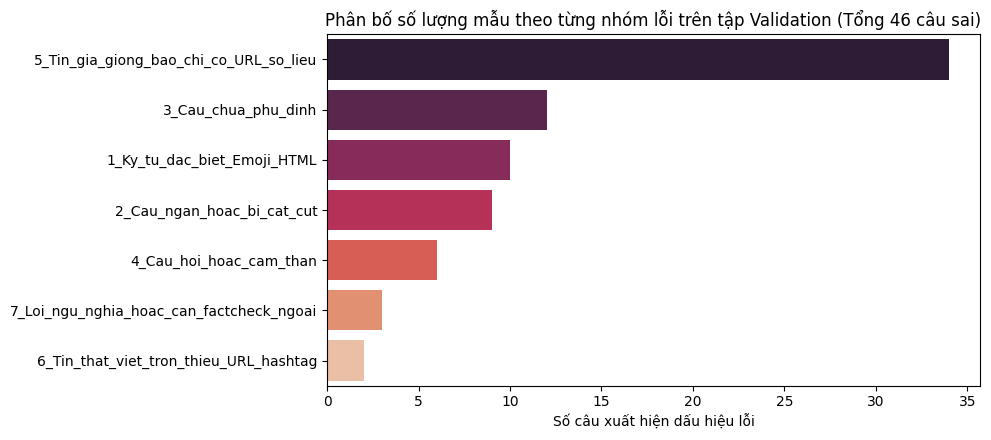

In [ ]:
# ==============================================================================
# CELL 5: PHÂN TÍCH LỖI TỰ ĐỘNG TỪ FALSE POSITIVE & FALSE NEGATIVE
# ==============================================================================
# Phân tích lỗi trên tập Validation để thiết kế cải tiến (không đụng tập Test)
df_val_err = df_val_preds[df_val_preds['label'] != df_val_preds['pred']].copy()
df_val_err['error_direction'] = np.where(
    (df_val_err['label'] == 0) & (df_val_err['pred'] == 1),
    'FP (Fake=0 -> đoán Real=1)',
    'FN (Real=1 -> đoán Fake=0)'
)

# Hàm tự động gắn nhóm lỗi (hạn chế làm thủ công)
def categorize_error_row(row):
    text = str(row['tweet'])
    direction = row['error_direction']
    words = text.split()
    tags = []

    if re.search(r'&amp;|&lt;|&gt;|&quot;|&#\d+;|[^\x00-\x7F]', text):
        tags.append('1_Ky_tu_dac_biet_Emoji_HTML')
    if len(words) <= 12 or re.search(r'\.\.\.|…', text):
        tags.append('2_Cau_ngan_hoac_bi_cat_cut')
    if re.search(r'\b(not|no|never|without|cannot|can\'t|doesn\'t|don\'t|isn\'t|aren\'t)\b', text, re.I):
        tags.append('3_Cau_chua_phu_dinh')
    if re.search(r'\?|!', text):
        tags.append('4_Cau_hoi_hoac_cam_than')
    if direction.startswith('FP') and re.search(r'http\S+|@\w+|RT\s+@|\d+', text):
        tags.append('5_Tin_gia_giong_bao_chi_co_URL_so_lieu')
    if direction.startswith('FN') and not re.search(r'http\S+|#\w+|@\w+', text):
        tags.append('6_Tin_that_viet_tron_thieu_URL_hashtag')

    if not tags:
        tags.append('7_Loi_ngu_nghia_hoac_can_factcheck_ngoai')

    return tags, tags[0]

tag_lists, primary_groups = zip(*[categorize_error_row(r) for _, r in df_val_err.iterrows()])
df_val_err['all_error_tags'] = ["; ".join(t) for t in tag_lists]
df_val_err['primary_error_group'] = primary_groups

print(f"=== TỔNG SỐ MẪU LỖI TRÊN TẬP VALIDATION (SEED {BEST_SEED}): {len(df_val_err)} / {len(df_val)} ===")
print(df_val_err['error_direction'].value_counts())

CAUSE_MAP = {
    '1_Ky_tu_dac_biet_Emoji_HTML': ('Nhiễu thực thể HTML (&amp;), ký tự non-ASCII/emoji', 'Giải mã HTML & chuẩn hóa ký tự nhiễu trước khi tokenize'),
    '2_Cau_ngan_hoac_bi_cat_cut': ('Thiếu ngữ cảnh do câu quá ngắn hoặc bị cắt cụt (...)', 'Khó sửa chỉ bằng tiền xử lý; cần thu thập đầy đủ bài viết gốc'),
    '3_Cau_chua_phu_dinh': ('Bài thật dùng từ phủ định bác bỏ tin đồn (chứa từ khóa tin giả)', 'Tăng cường mẫu đối lập phủ định / tinh chỉnh ngưỡng phân loại'),
    '4_Cau_hoi_hoac_cam_than': ('Dấu ? và ! thiên lệch mạnh về lớp Fake trong dữ liệu gốc', 'Giảm phụ thuộc dấu câu bề mặt & hiệu chỉnh ngưỡng quyết định'),
    '5_Tin_gia_giong_bao_chi_co_URL_so_lieu': ('Tin giả mượn lối tắt URL, @mention, RT, số liệu giống tin thật', 'Áp dụng Shortcut Dropout (ẩn ngẫu nhiên URL/RT/hashtag khi train)'),
    '6_Tin_that_viet_tron_thieu_URL_hashtag': ('Tin thật viết trơn, không có URL/hashtag (giống câu ngoài dữ liệu)', 'Áp dụng Shortcut Dropout để mô hình không ép câu thiếu URL thành Fake'),
    '7_Loi_ngu_nghia_hoac_can_factcheck_ngoai': ('Đòi hỏi tri thức kiểm chứng sự thật ngoài văn bản', 'Kết hợp truy xuất tri thức ngoài (RAG / Fact-checking API)')
}

all_tag_counts = {}
for tlist in tag_lists:
    for t in tlist:
        all_tag_counts[t] = all_tag_counts.get(t, 0) + 1

error_group_table = []
for grp, cnt in sorted(all_tag_counts.items(), key=lambda x: -x[1]):
    cause, fix = CAUSE_MAP[grp]
    decision = "CẦN THIẾT KẾ CẢI TIẾN" if cnt > 3 else "Ít mẫu (<=3), ưu tiên thấp"
    error_group_table.append({
        'Nhóm lỗi': grp,
        'Số câu mắc phải': cnt,
        'Tỉ lệ trên tổng lỗi (%)': round(cnt / len(df_val_err) * 100, 1),
        'Nguyên nhân': cause,
        'Quyết định': decision,
        'Hướng cải tiến đề xuất': fix
    })

df_error_summary = pd.DataFrame(error_group_table)
df_error_summary.to_csv("./roberta_results/error_analysis_groups_val.csv", index=False)
df_val_err.to_csv(f"./roberta_results/val_errors_categorized_seed{BEST_SEED}.csv", index=False)

print("\n=== BẢNG THỐNG KÊ NHÓM LỖI TỰ ĐỘNG & NGUYÊN NHÂN ===")
display(df_error_summary)

plt.figure(figsize=(10, 4.5))
sns.barplot(data=df_error_summary, y='Nhóm lỗi', x='Số câu mắc phải', hue='Nhóm lỗi', palette='rocket', legend=False)
plt.title(f"Phân bố số lượng mẫu theo từng nhóm lỗi trên tập Validation (Tổng {len(df_val_err)} câu sai)")
plt.xlabel("Số câu xuất hiện dấu hiệu lỗi")
plt.ylabel("")
plt.tight_layout()
plt.savefig("./roberta_results/error_groups_distribution.png", dpi=300)
plt.show()

## Cell 6: Thiết kế thí nghiệm cải tiến mô hình dựa trên lỗi (Trước vs Sau)

In [7]:
# ==============================================================================
# CELL 6: THIẾT KẾ THÍ NGHIỆM CẢI TIẾN MÔ HÌNH DỰA TRÊN LỖI (TRƯỚC VS SAU)
# ==============================================================================
# --- CẢI TIẾN A: TINH CHỈNH NGƯỠNG QUYẾT ĐỊNH (THRESHOLD TUNING) TRÊN VAL ---
best_tau = 0.50
best_val_f1_tau = 0.0
for tau in np.arange(0.10, 0.91, 0.02):
    preds_tau = (df_val_preds['prob_real'].values >= tau).astype(int)
    f1_tau = f1_score(df_val_preds['label'].values, preds_tau, average='weighted')
    if f1_tau > best_val_f1_tau:
        best_val_f1_tau = f1_tau
        best_tau = round(float(tau), 2)

test_preds_tau = (df_test_preds['prob_real'].values >= best_tau).astype(int)
test_f1_tau    = f1_score(df_test_preds['label'].values, test_preds_tau, average='weighted')
test_acc_tau   = accuracy_score(df_test_preds['label'].values, test_preds_tau)
cm_tau         = confusion_matrix(df_test_preds['label'].values, test_preds_tau, labels=[0, 1])

print(f"🔧 [Cải tiến A - Threshold Tuning] Ngưỡng tối ưu trên Val: tau = {best_tau} (Val F1w = {best_val_f1_tau:.6f})")
print(f"   → Trên Test: Acc = {test_acc_tau:.6f} | F1w = {test_f1_tau:.6f} | Tổng lỗi = {cm_tau[0,1] + cm_tau[1,0]}")

# --- CẢI TIẾN B: LÀM SẠCH LỖI HTML/KÝ TỰ ĐẶC BIỆT + SHORTCUT DROPOUT AUGMENTATION ---
def clean_special_noise(text):
    text = html.unescape(str(text))                        # Giải mã &amp;, &quot;...
    text = re.sub(r'[\r\n\t]+', ' ', text)              # Bỏ xuống dòng bất thường (nhiễu lớp Fake)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def strip_surface_shortcuts(text):
    """Loại bỏ lối tắt mạng xã hội (URL, RT, @mention, #) để tạo bản văn viết trơn."""
    t = clean_special_noise(text)
    t = re.sub(r'^RT\s+@\w+:\s*', '', t, flags=re.I)
    t = re.sub(r'http\S+|www\.\S+', '', t)
    t = re.sub(r'@\w+', '', t)
    t = re.sub(r'#', '', t)                                # Giữ lại nội dung hashtag, bỏ ký tự #
    t = re.sub(r'\s+', ' ', t).strip()
    return t

# Tạo tập Train cải tiến: giữ toàn bộ bản làm sạch + bổ sung 40% bản đã bỏ lối tắt
set_seed(BEST_SEED)
df_train_clean = df_train[['tweet', 'label']].copy()
df_train_clean['tweet'] = df_train_clean['tweet'].apply(clean_special_noise)

df_train_aug = df_train_clean.sample(frac=0.40, random_state=BEST_SEED).copy()
df_train_aug['tweet'] = df_train_aug['tweet'].apply(strip_surface_shortcuts)
df_train_aug = df_train_aug[df_train_aug['tweet'].str.len() > 15]

df_train_improved = pd.concat([df_train_clean, df_train_aug], ignore_index=True).sample(frac=1.0, random_state=BEST_SEED).reset_index(drop=True)

df_val_clean = df_val[['tweet', 'label']].copy()
df_val_clean['tweet'] = df_val_clean['tweet'].apply(clean_special_noise)

df_test_cleaned_text = df_test[['tweet', 'label']].copy()
df_test_cleaned_text['tweet'] = df_test_cleaned_text['tweet'].apply(clean_special_noise)

train_ds_imp = build_hf_dataset(df_train_improved)
val_ds_imp   = build_hf_dataset(df_val_clean)
test_ds_imp  = build_hf_dataset(df_test_cleaned_text)

print(f"\n🚀 [Cải tiến B - Fine-tune với Cleaning + Shortcut Dropout] Tập Train: {len(df_train)} → {len(df_train_improved)} mẫu (Seed {BEST_SEED})")
set_seed(BEST_SEED)
model_imp = RobertaForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
)

imp_out_dir = f"./roberta_checkpoints/improved_seed_{BEST_SEED}"
imp_kwargs = {
    "output_dir": imp_out_dir,
    "num_train_epochs": 3,
    "per_device_train_batch_size": 16,
    "per_device_eval_batch_size": 16,
    "learning_rate": 1.5e-5,
    "lr_scheduler_type": "cosine",
    "warmup_steps": 100,
    "weight_decay": 0.02,
    EVAL_STRATEGY_KEY: "epoch",
    "save_strategy": "epoch",
    "logging_strategy": "epoch",
    "save_total_limit": 1,
    "load_best_model_at_end": True,
    "metric_for_best_model": "f1_weighted",
    "greater_is_better": True,
    "fp16": torch.cuda.is_available(),
    "seed": BEST_SEED,
    "report_to": "none"
}
args_imp = TrainingArguments(**imp_kwargs)

trainer_imp = Trainer(
    model=model_imp,
    args=args_imp,
    train_dataset=train_ds_imp,
    eval_dataset=val_ds_imp,
    compute_metrics=compute_metrics
)
trainer_imp.train()

imp_best_dir = f"{imp_out_dir}/best_model"
trainer_imp.model.save_pretrained(imp_best_dir)
tokenizer.save_pretrained(imp_best_dir)
with open(os.path.join(imp_best_dir, "training_args.json"), "w", encoding="utf-8") as f:
    json.dump(args_imp.to_dict(), f, indent=2, default=str)

# Đánh giá mô hình cải tiến trên tập Test
pred_imp = trainer_imp.predict(test_ds_imp)
preds_imp_lbl = np.argmax(pred_imp.predictions, axis=-1)
y_test_true = df_test['label'].values

f1_w_imp = f1_score(y_test_true, preds_imp_lbl, average='weighted')
acc_imp  = accuracy_score(y_test_true, preds_imp_lbl)
cm_imp   = confusion_matrix(y_test_true, preds_imp_lbl, labels=[0, 1])

base_row = df_test_res[df_test_res['seed'] == BEST_SEED].iloc[0]
df_ablation = pd.DataFrame([
    {
        'Phiên bản': f'1. RoBERTa gốc (Seed {BEST_SEED}, tau=0.50)',
        'Test Accuracy': base_row['acc_test'],
        'Test F1 Weighted': base_row['f1_weighted_test'],
        'FP (Fake->Real)': base_row['FP_fake_as_real'],
        'FN (Real->Fake)': base_row['FN_real_as_fake'],
        'Tổng lỗi Test': base_row['total_errors']
    },
    {
        'Phiên bản': f'2. Cải tiến A: Threshold Tuning (tau={best_tau})',
        'Test Accuracy': test_acc_tau,
        'Test F1 Weighted': test_f1_tau,
        'FP (Fake->Real)': int(cm_tau[0, 1]),
        'FN (Real->Fake)': int(cm_tau[1, 0]),
        'Tổng lỗi Test': int(cm_tau[0, 1] + cm_tau[1, 0])
    },
    {
        'Phiên bản': '3. Cải tiến B: Clean HTML + Shortcut Dropout',
        'Test Accuracy': acc_imp,
        'Test F1 Weighted': f1_w_imp,
        'FP (Fake->Real)': int(cm_imp[0, 1]),
        'FN (Real->Fake)': int(cm_imp[1, 0]),
        'Tổng lỗi Test': int(cm_imp[0, 1] + cm_imp[1, 0])
    }
])
df_ablation.to_csv("./roberta_results/improvement_ablation_comparison.csv", index=False)
print("\n=== KẾT QUẢ THÍ NGHIỆM CẢI TIẾN DỰA TRÊN LỖI (TRƯỚC VS SAU) ===")
display(df_ablation.round(6))

🔧 [Cải tiến A - Threshold Tuning] Ngưỡng tối ưu trên Val: tau = 0.7 (Val F1w = 0.978956)
   → Trên Test: Acc = 0.977570 | F1w = 0.977560 | Tổng lỗi = 48


Map:   0%|          | 0/8988 [00:00<?, ? examples/s]

Map:   0%|          | 0/2140 [00:00<?, ? examples/s]

Map:   0%|          | 0/2140 [00:00<?, ? examples/s]


🚀 [Cải tiến B - Fine-tune với Cleaning + Shortcut Dropout] Tập Train: 6420 → 8988 mẫu (Seed 123)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


=== KẾT QUẢ THÍ NGHIỆM CẢI TIẾN DỰA TRÊN LỖI (TRƯỚC VS SAU) ===


,Phiên bản,Test Accuracy,Test F1 Weighted,FP (Fake->Real),FN (Real->Fake),Tổng lỗi Test
0,"1. RoBERTa gốc (Seed 123, tau=0.50)",0.977570,0.977560,33.0,15.0,48.0
1,2. Cải tiến A: Threshold Tuning (tau=0.7),0.977570,0.977560,33.0,15.0,48.0
2,3. Cải tiến B: Clean HTML + Shortcut Dropout,0.971495,0.971466,48.0,13.0,61.0


## Cell 7: Kiểm thử 10 câu ngoài (`external_10_sentences.csv`) & Demo tương tác

In [8]:
# ==============================================================================
# CELL 7: THỬ ĐÚNG 10 CÂU NGOÀI (external_10_sentences.csv) & DEMO NOTEBOOK
# ==============================================================================
ext_file_candidates = ["external_10_sentences.csv", "/content/external_10_sentences.csv", "data/external_10_sentences.csv"]
ext_path = next((p for p in ext_file_candidates if os.path.exists(p)), None)

if ext_path:
    df_ext_in = pd.read_csv(ext_path)
    print(f"✅ Đã đọc 10 câu ngoài từ file: {ext_path}")
else:
    df_ext_in = pd.DataFrame([
        {"id": 1,  "label": "real", "sentence": "WHO recommends washing your hands frequently with soap and water to reduce the risk of infection."},
        {"id": 2,  "label": "real", "sentence": "Wearing a mask in crowded indoor places can help reduce the spread of COVID-19."},
        {"id": 3,  "label": "real", "sentence": "The health ministry reported 1,250 new confirmed COVID-19 cases and 14 deaths in the last 24 hours."},
        {"id": 4,  "label": "real", "sentence": "Vaccines are approved only after clinical trials show they are safe and effective."},
        {"id": 5,  "label": "real", "sentence": "People with symptoms such as fever, cough or loss of taste or smell should get tested and isolate."},
        {"id": 6,  "label": "fake", "sentence": "Drinking bleach or disinfectant kills the coronavirus inside your body."},
        {"id": 7,  "label": "fake", "sentence": "5G mobile towers spread the coronavirus, so they must be shut down immediately."},
        {"id": 8,  "label": "fake", "sentence": "Eating raw garlic every morning completely prevents COVID-19 infection."},
        {"id": 9,  "label": "fake", "sentence": "Breaking: the government is hiding a secret cure for coronavirus that works in 24 hours."},
        {"id": 10, "label": "fake", "sentence": "COVID-19 vaccines contain microchips that let the government track everyone."}
    ])
    print("✅ Đang dùng bộ 10 câu chuẩn từ external_10_sentences.csv")

# Nạp cả 2 mô hình: Mô hình gốc (BEST_SEED) & Mô hình cải tiến (Shortcut Dropout)
model_orig = RobertaForSequenceClassification.from_pretrained(best_ckpt_paths[BEST_SEED]).to(DEVICE)
model_orig.eval()

model_better = RobertaForSequenceClassification.from_pretrained(imp_best_dir).to(DEVICE)
model_better.eval()

def infer_one(text, mdl):
    """Suy luận đọc trực tiếp id2label từ config của mô hình để tránh đảo nhãn."""
    inp = tokenizer(clean_special_noise(text), return_tensors="pt", truncation=True, padding="max_length", max_length=MAX_LEN).to(DEVICE)
    with torch.no_grad():
        logits = mdl(**inp).logits
        probs = torch.softmax(logits, dim=-1).cpu().numpy()[0]
        pred_id = int(np.argmax(probs))
    pred_name = mdl.config.id2label[pred_id].lower()
    return pred_name, float(probs[0]), float(probs[1])

ext_compare_rows = []
for _, r in df_ext_in.iterrows():
    true_lbl = str(r['label']).strip().lower()
    sent = str(r['sentence'])

    p_orig, pf_orig, pr_orig = infer_one(sent, model_orig)
    p_imp,  pf_imp,  pr_imp  = infer_one(sent, model_better)

    ext_compare_rows.append({
        'id': r['id'],
        'true_label': true_lbl,
        'orig_pred': p_orig,
        'orig_P_real': round(pr_orig, 4),
        'orig_ok': 'ĐÚNG' if p_orig == true_lbl else 'SAI',
        'improved_pred': p_imp,
        'improved_P_real': round(pr_imp, 4),
        'improved_ok': 'ĐÚNG' if p_imp == true_lbl else 'SAI',
        'sentence': sent
    })

df_ext_out = pd.DataFrame(ext_compare_rows)
df_ext_out.to_csv("./roberta_results/external_10_sentences_comparison.csv", index=False)

n_orig_ok = (df_ext_out['orig_ok'] == 'ĐÚNG').sum()
n_imp_ok  = (df_ext_out['improved_ok'] == 'ĐÚNG').sum()
print(f"\n=== KẾT QUẢ TRÊN 10 CÂU NGOÀI (external_10_sentences.csv) ===")
print(f"  - RoBERTa gốc (Seed {BEST_SEED})          : Đúng {n_orig_ok}/10 câu")
print(f"  - RoBERTa cải tiến (Shortcut Dropout): Đúng {n_imp_ok}/10 câu")
display(df_ext_out)

# Hàm Demo trực tiếp trong Notebook
ACTIVE_DEMO_MODEL = model_better if n_imp_ok >= n_orig_ok else model_orig
ACTIVE_MODEL_TAG  = "RoBERTa Cải tiến (Shortcut Dropout)" if n_imp_ok >= n_orig_ok else f"RoBERTa Gốc (Seed {BEST_SEED})"

def predict_covid_news(text):
    if not text or not text.strip():
        print("⚠️ Vui lòng nhập một câu tiếng Anh!")
        return
    pred_name, p_fake, p_real = infer_one(text, ACTIVE_DEMO_MODEL)
    conf = max(p_fake, p_real) * 100
    print("-" * 78)
    print(f"🤖 Mô hình Demo    : {ACTIVE_MODEL_TAG}")
    print(f"📝 Văn bản đầu vào : {text}")
    print(f"🔍 Dự đoán nhãn    : {pred_name.upper()} (Độ tự tin: {conf:.2f}%)")
    print(f"📊 Phân bố xác suất: P(fake=0) = {p_fake:.4f} | P(real=1) = {p_real:.4f}")
    print("-" * 78)

print("\n=== MINH HỌA DEMO NHẬP CÂU TRẢ NHÃN ===")
predict_covid_news(df_ext_in.iloc[0]['sentence'])
predict_covid_news(df_ext_in.iloc[5]['sentence'])

# Bỏ dấu # ở 5 dòng dưới khi muốn nhập trực tiếp từ bàn phím lúc bảo vệ:
# while True:
#     user_inp = input("\n👉 Nhập câu tiếng Anh cần kiểm tra (Nhấn Enter trống để thoát): ")
#     if not user_inp.strip():
#         break
#     predict_covid_news(user_inp)

✅ Đã đọc 10 câu ngoài từ file: external_10_sentences.csv


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


=== KẾT QUẢ TRÊN 10 CÂU NGOÀI (external_10_sentences.csv) ===
  - RoBERTa gốc (Seed 123)          : Đúng 5/10 câu
  - RoBERTa cải tiến (Shortcut Dropout): Đúng 7/10 câu


,id,true_label,orig_pred,orig_P_real,orig_ok,improved_pred,improved_P_real,improved_ok,sentence
0,1,real,fake,0.0006,SAI,fake,0.0009,SAI,WHO recommends washing your hands frequently w...
1,2,real,fake,0.0004,SAI,fake,0.0524,SAI,Wearing a mask in crowded indoor places can he...
2,3,real,fake,0.0018,SAI,fake,0.0007,SAI,"The health ministry reported 1,250 new confirm..."
3,4,real,fake,0.0005,SAI,real,0.7960,ĐÚNG,Vaccines are approved only after clinical tria...
4,5,real,fake,0.0009,SAI,real,0.9993,ĐÚNG,"People with symptoms such as fever, cough or l..."
5,6,fake,fake,0.0003,ĐÚNG,fake,0.0003,ĐÚNG,Drinking bleach or disinfectant kills the coro...
6,7,fake,fake,0.0003,ĐÚNG,fake,0.0003,ĐÚNG,"5G mobile towers spread the coronavirus, so th..."
7,8,fake,fake,0.0003,ĐÚNG,fake,0.0003,ĐÚNG,Eating raw garlic every morning completely pre...
8,9,fake,fake,0.0004,ĐÚNG,fake,0.0004,ĐÚNG,Breaking: the government is hiding a secret cu...
9,10,fake,fake,0.0003,ĐÚNG,fake,0.0002,ĐÚNG,COVID-19 vaccines contain microchips that let ...



=== MINH HỌA DEMO NHẬP CÂU TRẢ NHÃN ===
------------------------------------------------------------------------------
🤖 Mô hình Demo    : RoBERTa Cải tiến (Shortcut Dropout)
📝 Văn bản đầu vào : WHO recommends washing your hands frequently with soap and water to reduce the risk of infection.
🔍 Dự đoán nhãn    : FAKE (Độ tự tin: 99.91%)
📊 Phân bố xác suất: P(fake=0) = 0.9991 | P(real=1) = 0.0009
------------------------------------------------------------------------------
------------------------------------------------------------------------------
🤖 Mô hình Demo    : RoBERTa Cải tiến (Shortcut Dropout)
📝 Văn bản đầu vào : Drinking bleach or disinfectant kills the coronavirus inside your body.
🔍 Dự đoán nhãn    : FAKE (Độ tự tin: 99.97%)
📊 Phân bố xác suất: P(fake=0) = 0.9997 | P(real=1) = 0.0003
------------------------------------------------------------------------------


## Cell 8: Đóng gói Minh chứng gọn nhẹ đẩy lên GitHub (Không kèm trọng số nặng)

In [9]:
# ==============================================================================
# CELL 8: ĐÓNG GÓI FILE MINH CHỨNG ĐẨY LÊN GITHUB (HẠN NỘP 24/11)
# ==============================================================================
export_dir = "./binh_roberta_github_final"
if os.path.exists(export_dir):
    shutil.rmtree(export_dir)
os.makedirs(export_dir, exist_ok=True)

# 1. Copy toàn bộ kết quả CSV, JSON, PNG
for f in glob.glob("./roberta_results/*"):
    shutil.copy(f, export_dir)

# 2. Copy config.json, training_args.json và trainer_state.json của cả 5 seed
for seed in SEEDS:
    seed_export = os.path.join(export_dir, f"seed_{seed}_logs")
    os.makedirs(seed_export, exist_ok=True)

    for fname in ["config.json", "training_args.json", "tokenizer_config.json", "special_tokens_map.json"]:
        src = os.path.join(best_ckpt_paths[seed], fname)
        if os.path.exists(src):
            shutil.copy(src, seed_export)

    ckpt_folders = glob.glob(f"./roberta_checkpoints/seed_{seed}/checkpoint-*")
    if ckpt_folders:
        state_path = os.path.join(ckpt_folders[0], "trainer_state.json")
        if os.path.exists(state_path):
            shutil.copy(state_path, seed_export)

# 3. Copy config & log của phiên bản Cải tiến B
imp_export = os.path.join(export_dir, f"improved_seed_{BEST_SEED}_logs")
os.makedirs(imp_export, exist_ok=True)
for fname in ["config.json", "training_args.json", "tokenizer_config.json", "special_tokens_map.json"]:
    src = os.path.join(imp_best_dir, fname)
    if os.path.exists(src):
        shutil.copy(src, imp_export)
imp_ckpts = glob.glob(f"{imp_out_dir}/checkpoint-*")
if imp_ckpts:
    state_path = os.path.join(imp_ckpts[0], "trainer_state.json")
    if os.path.exists(state_path):
        shutil.copy(state_path, imp_export)

zip_path = shutil.make_archive("binh_roberta_github_final", "zip", export_dir)
print(f"✅ Đã đóng gói thành công: {zip_path}")
print("   Bao gồm: CSV/PNG kết quả 5 seed, báo cáo rò rỉ, 5 tiêu chí, phân tích lỗi tự động, cải tiến & 10 câu ngoài.")

# Tự động tải file ZIP xuống máy nếu đang chạy trên Google Colab
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("ℹ️ Không chạy trên Google Colab, hãy tải trực tiếp file 'binh_roberta_github_final.zip' trong thư mục hiện tại.")

✅ Đã đóng gói thành công: /content/binh_roberta_github_final.zip
   Bao gồm: CSV/PNG kết quả 5 seed, báo cáo rò rỉ, 5 tiêu chí, phân tích lỗi tự động, cải tiến & 10 câu ngoài.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>